# CNN Development on a Custom Dataset: Rock-Paper-Scissors Hand-Gesture Classification

**Course assignment:** Computer Vision and Pattern Recognition (CVPR), Mid Assignment   
**Student Name:** `Fariha Tasnim`  
**Student ID:** `23-50325-1`  
**Framework:** PyTorch  
**Platform:** Google Colab

---

### Objective
Design, train and evaluate a **custom Convolutional Neural Network (CNN), built from scratch without pretrained weights**, to classify hand-gesture images into three classes: **paper, rock and scissors**.



## 1. Import Libraries and Configuration

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import os
import copy
import time
import random
import zipfile

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# ---------- Reproducibility ----------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ---------- Device ----------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version :", torch.__version__)
print("Using device    :", device)

PyTorch version : 2.14.1+cu130
Using device    : cuda


### 1.1 Hyperparameters and Rationale

All important settings are collected in one place so they are easy to change and to justify.

| Hyperparameter | Value | Rationale |
|---|---|---|
| Input size (H x W) | 96 x 144 | Keeps the original 2:3 aspect ratio of the 200x300 images (no distortion) while using ~4x fewer pixels, so training is fast even on a CPU. A hand gesture is still clearly visible at this size. |
| Split (train/val/test) | 70 / 15 / 15 % (stratified) | Enough training data for a small CNN; validation set is used for model selection, test set is touched only once at the end. Stratification keeps the class proportions equal in all three sets. |
| Batch size | 32 | Small dataset (~1.5k training images). 32 gives frequent weight updates, a mild regularising effect from gradient noise, and fits easily in memory. |
| Optimizer | Adam, lr = 1e-3 | Adaptive learning rates give fast and stable convergence for a small CNN with Batch Normalization; 1e-3 is the standard well-tested starting value. |
| Weight decay | 1e-4 | Light L2 regularisation to reduce over-fitting. |
| Loss | Cross-entropy | Standard loss for single-label multi-class classification (applies log-softmax + negative log-likelihood to the raw logits). |
| Dropout | 0.4 | Regularisation in the classifier head, since the data set is small. |
| LR scheduler | ReduceLROnPlateau (factor 0.5, patience 3) | Halves the learning rate when validation loss stops improving, which allows fine-tuning of the weights near the end of training. |
| Max epochs | 30 | The data set is easy and small, so convergence happens well before 30 epochs. |
| Early stopping patience | 8 epochs | Stops training when validation accuracy has not improved, to avoid wasting time and over-fitting. The **best** epoch (not the last) is kept. |

In [5]:
# ---------- Configuration ----------
CLASS_NAMES   = ["paper", "rock", "scissors"]   # folder names = class labels
NUM_CLASSES   = len(CLASS_NAMES)

IMG_H, IMG_W  = 96, 144      # keeps 2:3 aspect ratio of the original 200 x 300 images
BATCH_SIZE    = 32
EPOCHS        = 30
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 1e-4
DROPOUT       = 0.4
ES_PATIENCE   = 8            # early-stopping patience (epochs)

VAL_FRAC      = 0.15
TEST_FRAC     = 0.15

ZIP_PATH      = "archive.zip"   # change if your zip file is somewhere else
EXTRACT_DIR   = "rps_data"
MODEL_PATH    = "CNN_23-50325-1.pth"

## 2. Load and Explore the Dataset

### 2.1 Dataset Description

| Item | Description |
|---|---|
| **Name** | Rock Paper Scissors Dataset (`rpc-cv-images`) |
| **Source** | Kaggle: <https://www.kaggle.com/datasets/drgfreeman/rockpaperscissors> |
| **Author / License** | Julien de la Bruere-Terreault, CC-BY-SA 4.0 |
| **Task** | 3-class image classification of hand gestures (rock, paper, scissors) |
| **Total images** | 2,188 RGB images (`.png`) |
| **Image size** | 300 x 200 pixels (width x height) |
| **Classes** | `paper`, `rock`, `scissors` (one sub-folder per class) |
| **Characteristics** | Photos taken on a uniform green background with fairly consistent lighting and white balance. |

> **Note:** the exact number of images per class is counted from the files in the cell below. (The author's README lists 726 / 710 / 752, while the downloaded copy contains 726 / 712 / 750; the total is the same, 2,188.) The zip file also contains a second, identical copy of the data inside a nested `rps-cv-images/` folder; the code below uses only **one** copy so that no image is counted twice.

**Why this dataset?** It has multiple classes (3), is small enough to train quickly, has balanced classes, and the folder-per-class structure makes it easy to load. It is also a genuinely visual problem: the classes differ only by the *shape* of the hand, which is exactly what convolutional filters are good at detecting.

In [6]:
# ---------- Unzip (only if needed) ----------
if os.path.exists(ZIP_PATH) and not os.path.isdir(EXTRACT_DIR):
    print("Extracting", ZIP_PATH, "...")
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_DIR)

def find_data_root(base):
    """Return the shallowest folder under `base` that contains all class folders."""
    best = None
    for root, dirs, _ in os.walk(base):
        if set(CLASS_NAMES).issubset(set(dirs)):
            depth = root.count(os.sep)
            if best is None or depth < best[0]:
                best = (depth, root)
    return best[1] if best else None

DATA_ROOT = None
for base in [EXTRACT_DIR, "/kaggle/input", "."]:
    if os.path.isdir(base):
        DATA_ROOT = find_data_root(base)
        if DATA_ROOT:
            break

# ---------- Fallback: download from Kaggle automatically (no manual upload needed) ----------
if DATA_ROOT is None:
    print("archive.zip not found -> downloading the dataset with kagglehub ...")
    try:
        import kagglehub
    except ImportError:
        os.system("pip -q install kagglehub")
        import kagglehub
    kh_path = kagglehub.dataset_download("drgfreeman/rockpaperscissors")
    DATA_ROOT = find_data_root(kh_path)

assert DATA_ROOT is not None, "Dataset not found. Upload archive.zip, fix ZIP_PATH, or check your internet connection."
print("Dataset folder:", DATA_ROOT)

archive.zip not found -> downloading the dataset with kagglehub ...


100%|██████████| 306M/306M [00:15<00:00, 20.4MB/s]

Extracting files...


Dataset folder: /root/.cache/kagglehub/datasets/drgfreeman/rockpaperscissors/versions/2


In [7]:
# ---------- Collect file paths + labels, load every image once (resized) ----------
paths, labels = [], []
for class_idx, cname in enumerate(CLASS_NAMES):
    folder = os.path.join(DATA_ROOT, cname)
    for fname in sorted(os.listdir(folder)):
        if fname.lower().endswith((".png", ".jpg", ".jpeg")):
            paths.append(os.path.join(folder, fname))
            labels.append(class_idx)
labels = np.array(labels)

images, orig_sizes, orig_modes = [], set(), set()
for p in paths:
    with Image.open(p) as im:
        orig_sizes.add(im.size)
        orig_modes.add(im.mode)
        images.append(im.convert("RGB").resize((IMG_W, IMG_H), Image.BILINEAR))   # PIL size = (W, H)

print(f"Total images        : {len(images)}")
print(f"Original image sizes: {orig_sizes}  (W, H)")
print(f"Original colour mode: {orig_modes}")
print(f"Resized to (H, W)   : ({IMG_H}, {IMG_W})")
print()
counts = np.bincount(labels, minlength=NUM_CLASSES)
for cname, c in zip(CLASS_NAMES, counts):
    print(f"  {cname:<9}: {c:4d} images ({100*c/len(labels):.1f} %)")

Total images        : 2188
Original image sizes: {(300, 200)}  (W, H)
Original colour mode: {'RGB'}
Resized to (H, W)   : (96, 144)

  paper    :  712 images (32.5 %)
  rock     :  726 images (33.2 %)
  scissors :  750 images (34.3 %)


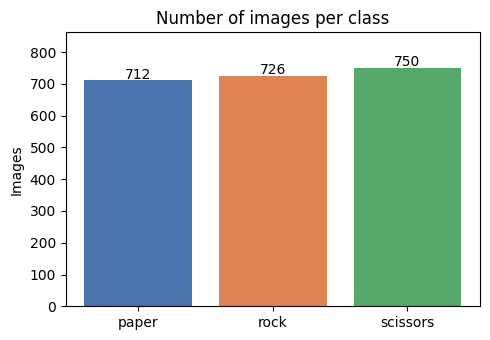

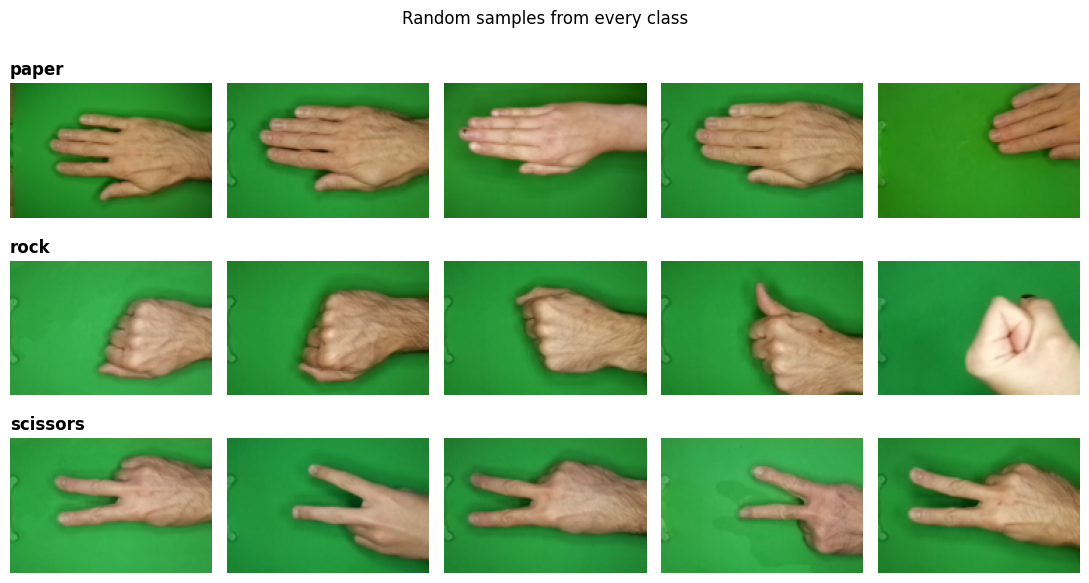

In [8]:
# ---------- Class distribution ----------
plt.figure(figsize=(5, 3.5))
bars = plt.bar(CLASS_NAMES, counts, color=["#4c72b0", "#dd8452", "#55a868"])
for b, c in zip(bars, counts):
    plt.text(b.get_x() + b.get_width() / 2, c + 5, str(c), ha="center")
plt.title("Number of images per class")
plt.ylabel("Images")
plt.ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()

# ---------- Sample images ----------
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(11, 6))
rng = np.random.RandomState(0)
for r, cname in enumerate(CLASS_NAMES):
    chosen = rng.choice(np.where(labels == r)[0], 5, replace=False)
    for c, i in enumerate(chosen):
        axes[r, c].imshow(images[i])
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(cname, loc="left", fontsize=12, fontweight="bold")
plt.suptitle("Random samples from every class", y=1.0)
plt.tight_layout()
plt.show()

**Observations**
- The three classes are almost perfectly balanced, so plain *accuracy* is a fair metric (no need for class weights or re-sampling), but we still report per-class precision, recall and F1.
- All images share the same size and a uniform green background, so the model can concentrate on the hand shape.
- The same gesture can appear at different positions, angles and lighting, which motivates data augmentation.

## 3. Data Preprocessing and Augmentation

**Splitting.** The data is divided into **70 % train / 15 % validation / 15 % test** using a *stratified* split, so every subset keeps the same class proportions. The split is done on the image indices **before** any augmentation or normalisation statistics are computed, so no information leaks from validation/test into training.

**Preprocessing (all sets):**
1. Resize to 96 x 144 (done once while loading).
2. Convert to tensor (pixel values scaled to [0, 1]).
3. Normalise each RGB channel with the **mean and standard deviation computed from the training set only**. This centres the inputs and makes optimisation faster and more stable.

**Augmentation (training set only):** random horizontal flip, random rotation (up to 15 degrees) and mild brightness/contrast/saturation jitter. These imitate the natural variation of a player's hand (left/right hand, tilt, lighting) and reduce over-fitting. Hue jitter is deliberately **not** used, because it would change the green background colour in an unrealistic way. Validation and test images are **never** augmented, so their scores are a fair measurement.

In [9]:
# ---------- Stratified 70/15/15 split ----------
idx = np.arange(len(labels))
train_idx, temp_idx = train_test_split(
    idx, test_size=VAL_FRAC + TEST_FRAC, stratify=labels, random_state=SEED)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC),
    stratify=labels[temp_idx], random_state=SEED)

print(f"Train: {len(train_idx)} | Validation: {len(val_idx)} | Test: {len(test_idx)}\n")
print(f"{'class':<10}{'train':>8}{'val':>8}{'test':>8}")
for k, cname in enumerate(CLASS_NAMES):
    print(f"{cname:<10}{(labels[train_idx]==k).sum():>8}{(labels[val_idx]==k).sum():>8}{(labels[test_idx]==k).sum():>8}")

# ---------- Channel mean / std from the TRAINING images only ----------
s, sq, n_pix = np.zeros(3), np.zeros(3), 0
for i in train_idx:
    a = np.asarray(images[i], dtype=np.float64) / 255.0
    s += a.sum(axis=(0, 1))
    sq += (a ** 2).sum(axis=(0, 1))
    n_pix += a.shape[0] * a.shape[1]
MEAN = (s / n_pix).tolist()
STD = np.sqrt(sq / n_pix - (s / n_pix) ** 2).tolist()
print("\nTraining-set channel mean:", [round(m, 4) for m in MEAN])
print("Training-set channel std :", [round(v, 4) for v in STD])

Train: 1531 | Validation: 328 | Test: 329

class        train     val    test
paper          498     107     107
rock           508     109     109
scissors       525     112     113

Training-set channel mean: [0.323, 0.5492, 0.2605]
Training-set channel std : [0.2542, 0.1, 0.1316]


In [10]:
# ---------- Transforms ----------
train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([           # validation / test: NO augmentation
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# ---------- Dataset class (images are already in memory, so loading is fast) ----------
class RPSDataset(Dataset):
    def __init__(self, imgs, lbls, transform):
        self.imgs, self.lbls, self.transform = imgs, lbls, transform
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, i):
        return self.transform(self.imgs[i]), int(self.lbls[i])

train_ds = RPSDataset([images[i] for i in train_idx], labels[train_idx], train_tf)
val_ds   = RPSDataset([images[i] for i in val_idx],   labels[val_idx],   eval_tf)
test_ds  = RPSDataset([images[i] for i in test_idx],  labels[test_idx],  eval_tf)

# ---------- Data loaders ----------
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=g, num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

xb, yb = next(iter(train_loader))
print("One training batch ->", "images:", tuple(xb.shape), "| labels:", tuple(yb.shape))
print("Batches per epoch  -> train:", len(train_loader), "| val:", len(val_loader), "| test:", len(test_loader))

One training batch -> images: (32, 3, 96, 144) | labels: (32,)
Batches per epoch  -> train: 48 | val: 11 | test: 11


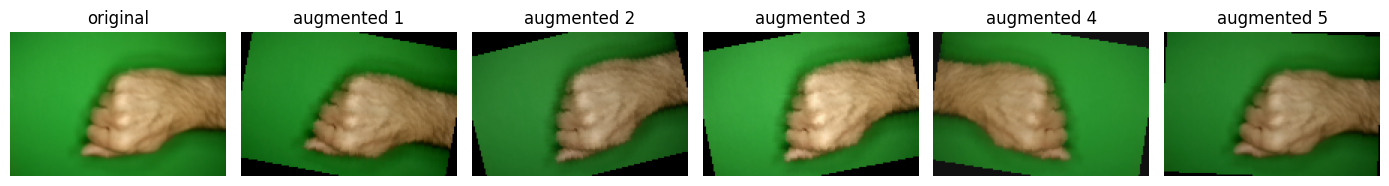

In [11]:
# ---------- Visualise the augmentation ----------
def denorm(t):
    """Undo normalisation so a tensor can be shown with imshow."""
    m = torch.tensor(MEAN).view(3, 1, 1)
    sd = torch.tensor(STD).view(3, 1, 1)
    return (t * sd + m).clamp(0, 1).permute(1, 2, 0).numpy()

sample = train_ds.imgs[0]
fig, axes = plt.subplots(1, 6, figsize=(14, 2.8))
axes[0].imshow(sample); axes[0].set_title("original"); axes[0].axis("off")
for k in range(1, 6):
    axes[k].imshow(denorm(train_tf(sample))); axes[k].set_title(f"augmented {k}"); axes[k].axis("off")
plt.tight_layout()
plt.show()

## 4. Define the CNN Architecture

A **custom CNN built from scratch** with four convolutional blocks followed by a small classifier.

```
Input (3 x 96 x 144)
 |-- Block 1: Conv3x3(3 -> 32)    + BatchNorm + ReLU + MaxPool2  -> 32 x 48 x 72
 |-- Block 2: Conv3x3(32 -> 64)   + BatchNorm + ReLU + MaxPool2  -> 64 x 24 x 36
 |-- Block 3: Conv3x3(64 -> 128)  + BatchNorm + ReLU + MaxPool2  -> 128 x 12 x 18
 |-- Block 4: Conv3x3(128 -> 256) + BatchNorm + ReLU + MaxPool2  -> 256 x 6 x 9
 |-- Global Average Pooling                                      -> 256
 |-- Dropout(0.4) -> Linear(256 -> 128) -> ReLU -> Dropout(0.4)
 |-- Linear(128 -> 3)   (raw logits; softmax is inside the cross-entropy loss)
```

**Design justification**
- **Stacked 3x3 convolutions with growing channels (32 -> 64 -> 128 -> 256):** early layers learn simple edges and colour blobs, deeper layers combine them into finger and palm shapes. Doubling the channels while halving the spatial size is a standard way to keep the compute per layer balanced.
- **Batch Normalization:** stabilises and speeds up training and acts as a mild regulariser. (Convolution bias is turned off because BatchNorm already has a learnable shift.)
- **ReLU:** cheap, non-saturating non-linearity that avoids vanishing gradients.
- **Max-pooling (2x2):** halves the resolution, enlarges the receptive field and gives small translation invariance.
- **Global Average Pooling instead of a big flatten + dense layer:** far fewer parameters (less over-fitting on a small data set) and the network can accept any input size.
- **Dropout (0.4)** in the classifier for extra regularisation.
- **Small model (~0.4 M parameters):** the task is simple (3 classes, clean background), so a large network is unnecessary; the saved weights are only ~2 MB, well under the 20 MB limit for GitHub.

In [12]:
class RPSNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, dropout=DROPOUT):
        super().__init__()

        def conv_block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(c_out),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=2),
            )

        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
        )
        self.gap = nn.AdaptiveAvgPool2d(1)            # global average pooling -> 256 x 1 x 1
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        return self.classifier(x)

model = RPSNet().to(device)
print(model)

RPSNet(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0

In [13]:
# ---------- Detailed layer-by-layer summary (no extra library needed) ----------
def model_summary(model, input_size=(1, 3, IMG_H, IMG_W)):
    rows, hooks = [], []

    def hook(module, inp, out):
        n_params = sum(p.numel() for p in module.parameters(recurse=False))
        rows.append((module.__class__.__name__, tuple(out.shape[1:]), n_params))

    for m in model.modules():
        if len(list(m.children())) == 0:          # leaf layers only
            hooks.append(m.register_forward_hook(hook))

    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(torch.zeros(input_size).to(device))
    for h in hooks:
        h.remove()
    model.train(was_training)

    print("-" * 62)
    print(f"{'Layer (type)':<22}{'Output shape (C,H,W)':<26}{'Params':>12}")
    print("=" * 62)
    for i, (name, shape, p) in enumerate(rows, 1):
        print(f"{i:>2}. {name:<18}{str(shape):<26}{p:>12,}")
    print("=" * 62)
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total parameters     : {total:,}")
    print(f"Trainable parameters : {trainable:,}")
    print(f"Approx. size (fp32)  : {total * 4 / 1024 ** 2:.2f} MB")
    print("-" * 62)

model_summary(model)

--------------------------------------------------------------
Layer (type)          Output shape (C,H,W)            Params
 1. Conv2d            (32, 96, 144)                      864
 2. BatchNorm2d       (32, 96, 144)                       64
 3. ReLU              (32, 96, 144)                        0
 4. MaxPool2d         (32, 48, 72)                         0
 5. Conv2d            (64, 48, 72)                    18,432
 6. BatchNorm2d       (64, 48, 72)                       128
 7. ReLU              (64, 48, 72)                         0
 8. MaxPool2d         (64, 24, 36)                         0
 9. Conv2d            (128, 24, 36)                   73,728
10. BatchNorm2d       (128, 24, 36)                      256
11. ReLU              (128, 24, 36)                        0
12. MaxPool2d         (128, 12, 18)                        0
13. Conv2d            (256, 12, 18)                  294,912
14. BatchNorm2d       (256, 12, 18)                      512
15. ReLU              

## 5. Training Loop with Validation

- **Loss:** `nn.CrossEntropyLoss` (multi-class classification).
- **Optimizer:** Adam (lr = 1e-3, weight decay = 1e-4).
- **Scheduler:** `ReduceLROnPlateau` on the validation loss.
- **Model selection:** after every epoch the model is evaluated on the **validation** set; the weights with the best validation accuracy are kept (ties are broken by lower validation loss). Training stops early if there is no improvement for 8 epochs.
- The test set is **not** used anywhere in this section.

In [14]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

def run_epoch(model, loader, criterion, optimizer=None):
    """One pass over `loader`. Trains if an optimizer is given, otherwise only evaluates."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if training:
                optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(dim=1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

In [15]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
best_val_acc, best_val_loss, best_epoch = 0.0, float("inf"), 0
best_state = copy.deepcopy(model.state_dict())
epochs_no_improve = 0
start = time.time()

print(f"{'Epoch':>5} | {'Train loss':>10} {'Train acc':>9} | {'Val loss':>8} {'Val acc':>8} | {'LR':>8}")
print("-" * 66)
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
    va_loss, va_acc = run_epoch(model, val_loader, criterion)
    scheduler.step(va_loss)
    lr_now = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
    history["val_loss"].append(va_loss);   history["val_acc"].append(va_acc)
    history["lr"].append(lr_now)

    improved = (va_acc > best_val_acc) or (va_acc == best_val_acc and va_loss < best_val_loss)
    if improved:
        best_val_acc, best_val_loss, best_epoch = va_acc, va_loss, epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
        flag = "  <- best"
    else:
        epochs_no_improve += 1
        flag = ""
    print(f"{epoch:>5} | {tr_loss:>10.4f} {tr_acc:>9.4f} | {va_loss:>8.4f} {va_acc:>8.4f} | {lr_now:>8.1e}{flag}")

    if epochs_no_improve >= ES_PATIENCE:
        print(f"\nEarly stopping: no improvement for {ES_PATIENCE} epochs.")
        break

print(f"\nTraining finished in {(time.time() - start) / 60:.1f} min. "
      f"Best epoch = {best_epoch} (val acc = {best_val_acc:.4f}, val loss = {best_val_loss:.4f})")

model.load_state_dict(best_state)    # restore the best weights

Epoch | Train loss Train acc | Val loss  Val acc |       LR
------------------------------------------------------------------
    1 |     0.7014    0.7172 |   0.2604   0.9146 |  1.0e-03  <- best
    2 |     0.2126    0.9379 |   0.1481   0.9756 |  1.0e-03  <- best
    3 |     0.1414    0.9582 |   1.1791   0.5945 |  1.0e-03
    4 |     0.1474    0.9562 |   0.1174   0.9665 |  1.0e-03
    5 |     0.0943    0.9726 |   0.1183   0.9848 |  1.0e-03  <- best
    6 |     0.1323    0.9549 |   0.1941   0.9512 |  1.0e-03
    7 |     0.0907    0.9758 |   0.0925   0.9726 |  1.0e-03
    8 |     0.0635    0.9869 |   0.0958   0.9726 |  1.0e-03
    9 |     0.0701    0.9771 |   0.0753   0.9787 |  1.0e-03
   10 |     0.0675    0.9804 |   0.3127   0.8933 |  1.0e-03
   11 |     0.0534    0.9817 |   0.0540   0.9909 |  1.0e-03  <- best
   12 |     0.0477    0.9837 |   0.0454   0.9909 |  1.0e-03  <- best
   13 |     0.0623    0.9798 |   1.1657   0.7409 |  1.0e-03
   14 |     0.0398    0.9863 |   0.5255   0.8537

<All keys matched successfully>

## 6. Evaluate the Model on the Test Set

The test set (never used for training or model selection) is evaluated **once**, using the best weights. We report accuracy, per-class precision / recall / F1 and the confusion matrix.

In [16]:
@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    preds, ys, probs = [], [], []
    for x, y in loader:
        out = model(x.to(device))
        preds.append(out.argmax(1).cpu()); ys.append(y); probs.append(torch.softmax(out, 1).cpu())
    return torch.cat(preds).numpy(), torch.cat(ys).numpy(), torch.cat(probs).numpy()

test_loss, test_acc = run_epoch(model, test_loader, criterion)
test_preds, test_true, test_probs = predict_all(model, test_loader)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_acc * 100:.2f} %   ({(test_preds == test_true).sum()} / {len(test_true)} correct)")
print(f"Macro F1-score: {f1_score(test_true, test_preds, average='macro'):.4f}\n")

print(classification_report(test_true, test_preds, target_names=CLASS_NAMES, digits=4))
report_dict = classification_report(test_true, test_preds, target_names=CLASS_NAMES, output_dict=True)

Test loss     : 0.0100
Test accuracy : 99.70 %   (328 / 329 correct)
Macro F1-score: 0.9970

              precision    recall  f1-score   support

       paper     1.0000    0.9907    0.9953       107
        rock     1.0000    1.0000    1.0000       109
    scissors     0.9912    1.0000    0.9956       113

    accuracy                         0.9970       329
   macro avg     0.9971    0.9969    0.9970       329
weighted avg     0.9970    0.9970    0.9970       329



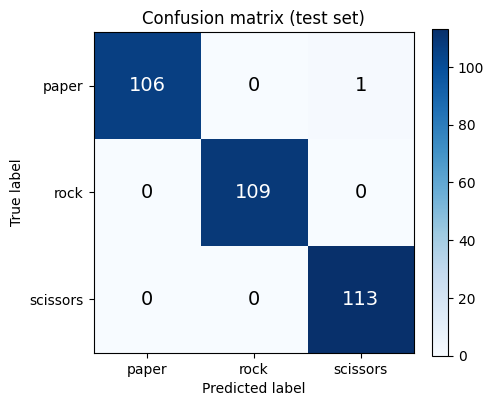

In [17]:
# ---------- Confusion matrix ----------
cm = confusion_matrix(test_true, test_preds)

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
ax.set_title("Confusion matrix (test set)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
plt.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.show()

## 7. Visualisations (Loss / Accuracy Curves)

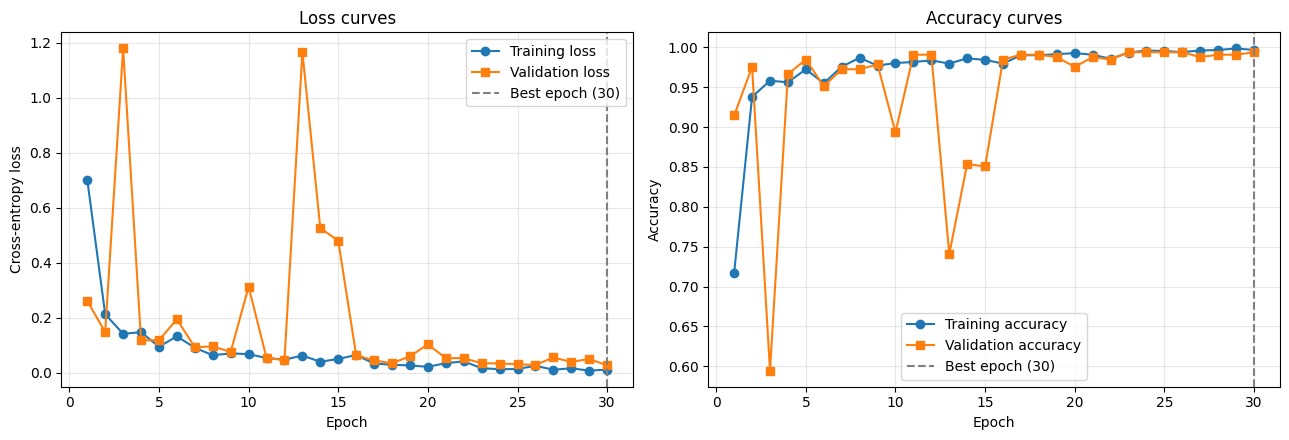

In [18]:
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_range, history["train_loss"], "o-", label="Training loss")
axes[0].plot(epochs_range, history["val_loss"], "s-", label="Validation loss")
axes[0].axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
axes[0].set_title("Loss curves"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, history["train_acc"], "o-", label="Training accuracy")
axes[1].plot(epochs_range, history["val_acc"], "s-", label="Validation accuracy")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
axes[1].set_title("Accuracy curves"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 7.0 Explanation of the curves for this run

> **Fill in after running the notebook, using the plots above.**



- **Loss curves:** Training loss fell from about **0.7014 to 0.0111**. Validation loss reached its lowest value of **0.0268 at epoch 30** (the dashed line). It showed some fluctuations during training but finished at its lowest value.

- **Accuracy curves:** Validation accuracy reached **99.39%** at the best epoch, against **99.67%** training accuracy. The gap of **0.28 percentage points** means little overfitting.

- **Learning-rate drops:** The learning rate was halved at epochs **16 and 22** (see the LR column of the training log), after which validation loss improved.

- **Why the curves look like this:** Data augmentation and dropout are active only during training, so early training accuracy can be lower than validation accuracy.



1 test image(s) were mis-classified.


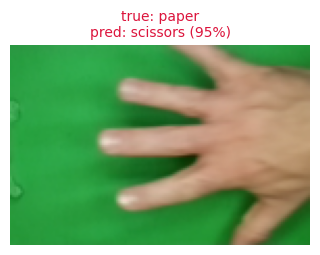

In [19]:
# ---------- Mis-classified test images (if any) ----------
wrong = np.where(test_preds != test_true)[0]
print(f"{len(wrong)} test image(s) were mis-classified.")

if len(wrong) > 0:
    show = wrong[:8]
    cols = min(4, len(show))
    rows = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.3 * cols, 2.8 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, i in zip(axes, show):
        ax.imshow(test_ds.imgs[i])
        ax.set_title(f"true: {CLASS_NAMES[test_true[i]]}\npred: {CLASS_NAMES[test_preds[i]]} "
                     f"({test_probs[i].max()*100:.0f}%)", fontsize=10, color="crimson")
    plt.tight_layout()
    plt.show()

### 7.1 Save and Reload the Trained Model

Only the learned weights (`state_dict`) are stored, which is the recommended PyTorch way. To use the model later, create a new `RPSNet()` and load the weights into it. The check below confirms that the reloaded model gives exactly the same test accuracy.

Saved 'CNN_23-50325-1.pth'  (1.62 MB) -> small enough to upload to GitHub (< 20 MB).
Test accuracy of the original model : 99.70 %
Test accuracy of the reloaded model : 99.70 %


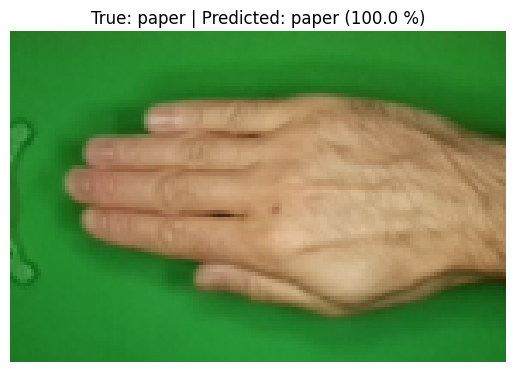

In [20]:
# ---------- Save ----------
torch.save(model.state_dict(), MODEL_PATH)
size_mb = os.path.getsize(MODEL_PATH) / 1024 ** 2
print(f"Saved '{MODEL_PATH}'  ({size_mb:.2f} MB)", "-> small enough to upload to GitHub (< 20 MB)." if size_mb < 20 else "-> larger than 20 MB, keep a local copy only.")

# ---------- Reload into a brand-new model and verify ----------
loaded_model = RPSNet().to(device)
loaded_model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
loaded_model.eval()

_, reloaded_acc = run_epoch(loaded_model, test_loader, criterion)
print(f"Test accuracy of the original model : {test_acc * 100:.2f} %")
print(f"Test accuracy of the reloaded model : {reloaded_acc * 100:.2f} %")
assert abs(test_acc - reloaded_acc) < 1e-9, "Reloaded model does not match!"

# ---------- Predict a single image with the reloaded model ----------
i = 0
x = eval_tf(test_ds.imgs[i]).unsqueeze(0).to(device)
with torch.no_grad():
    p = torch.softmax(loaded_model(x), dim=1)[0].cpu().numpy()
plt.imshow(test_ds.imgs[i]); plt.axis("off")
plt.title(f"True: {CLASS_NAMES[test_true[i]]} | Predicted: {CLASS_NAMES[p.argmax()]} ({p.max()*100:.1f} %)")
plt.show()

## 8. Analysis and Discussion of Results

The next cell reads the numbers produced by **this run** and writes a short summary, so the text always matches the actual results. A written interpretation follows it.

In [21]:
bi = best_epoch - 1
tr_acc_b, va_acc_b = history["train_acc"][bi], history["val_acc"][bi]
tr_loss_b, va_loss_b = history["train_loss"][bi], history["val_loss"][bi]
gap = tr_acc_b - va_acc_b

print(f"* Training stopped after {len(history['train_loss'])} epochs; the best epoch was {best_epoch}.")
print(f"* At the best epoch: train acc = {tr_acc_b*100:.2f} %, val acc = {va_acc_b*100:.2f} %, "
      f"train loss = {tr_loss_b:.4f}, val loss = {va_loss_b:.4f}.")
print(f"* Final TEST accuracy = {test_acc*100:.2f} % (macro F1 = {f1_score(test_true, test_preds, average='macro'):.4f}).")

if gap > 0.05:
    print(f"* Train accuracy is {gap*100:.1f} points above validation accuracy -> some over-fitting.")
elif gap < -0.01:
    print(f"* Validation accuracy is {-gap*100:.1f} points ABOVE training accuracy. This is normal here: "
          "augmentation and dropout make the training task harder than the clean validation images.")
else:
    print(f"* Train/validation gap is only {abs(gap)*100:.1f} points -> the model generalises well, no serious over-fitting.")

if abs(va_acc_b - test_acc) <= 0.03:
    print("* Validation and test accuracy are close, so the validation set was a reliable estimate of unseen-data performance.")
else:
    print("* Validation and test accuracy differ by more than 3 points; with a small test set (a few hundred images) "
          "a handful of images can cause this.")

per_class_recall = {c: report_dict[c]["recall"] for c in CLASS_NAMES}
weakest = min(per_class_recall, key=per_class_recall.get)
print(f"* Class with the lowest recall: '{weakest}' ({per_class_recall[weakest]*100:.1f} %).")

off = cm.copy(); np.fill_diagonal(off, 0)
if off.max() > 0:
    a, b = np.unravel_index(off.argmax(), off.shape)
    print(f"* Most frequent confusion: true '{CLASS_NAMES[a]}' predicted as '{CLASS_NAMES[b]}' ({off[a, b]} image(s)).")
else:
    print("* No confusions at all on the test set.")

* Training stopped after 30 epochs; the best epoch was 30.
* At the best epoch: train acc = 99.67 %, val acc = 99.39 %, train loss = 0.0111, val loss = 0.0268.
* Final TEST accuracy = 99.70 % (macro F1 = 0.9970).
* Train/validation gap is only 0.3 points -> the model generalises well, no serious over-fitting.
* Validation and test accuracy are close, so the validation set was a reliable estimate of unseen-data performance.
* Class with the lowest recall: 'paper' (99.1 %).
* Most frequent confusion: true 'paper' predicted as 'scissors' (1 image(s)).


### 8.1 Written interpretation of this run

> **Fill in after running the notebook, using your own results from Sections 5 to 7 and the summary printed above.**


- **Test performance:** The model reached a test accuracy of **99.70%** (macro F1 = **0.9970**) on **329 unseen images**, with the best validation accuracy of **99.39%** at epoch **30**.

- **Per-class results:** Precision was highest for **Paper and Rock (100%)**, while the lowest precision was for **Scissors (99.12%)**. Recall was highest for **Rock and Scissors (100%)** and lowest for **Paper (99.07%)**. The most common mistake was **Paper** predicted as **Scissors** (1 image).

- **Generalisation:** Validation and test accuracy are **close** (99.39% and 99.70%), so the validation set was **a reliable** estimate of unseen-data performance.

- **Caveat:** The images share a uniform green background and similar lighting, so this score may not carry over to photos taken under different backgrounds, lighting conditions, or environments.

**How to read the curves (Section 7)**
- **Loss curves:** the training loss should fall steadily. If the validation loss falls together with it and then flattens, the model has learned what it can from the data; if the validation loss starts to *rise* while the training loss keeps falling, the model is over-fitting. The dashed vertical line marks the epoch whose weights were kept.
- **Accuracy curves:** the same story in terms of correct predictions. Validation accuracy may be equal to or higher than training accuracy in the early epochs because the training images are augmented and dropout is active during training, while validation images are clean and dropout is off.
- **Learning-rate drops:** when the validation loss stops improving, `ReduceLROnPlateau` halves the learning rate (the `LR` column of the training log), which usually produces a small extra improvement.

**Why the model works well on this data set**
- The classes differ in the *global shape* of the hand (closed fist, open palm, two fingers), which the stacked convolution + pooling hierarchy captures well.
- The uniform green background removes distracting clutter, so the problem is relatively easy for a small CNN.
- Batch normalization, dropout, weight decay, data augmentation and best-epoch selection all help to prevent over-fitting on only ~1,500 training images.

**Limitations**
- All images come from one capture set-up (same background, camera and similar lighting). Accuracy on photos with a cluttered background, different skin tones or different cameras may be **much lower**; a high test score here does not guarantee real-world robustness.
- The test set is small (~330 images), so one image changes the accuracy by about 0.3 percentage points.
- The model was trained from scratch; no pretrained features were used.

## 9. Conclusions and Future Work

### Conclusions
- A compact custom CNN (4 convolution blocks + global average pooling + a small dense head, about 0.42 M parameters) was trained from scratch on the 3-class Rock-Paper-Scissors data set using the Adam optimizer and cross-entropy loss.
- A stratified 70/15/15 split, training-only normalisation statistics and training-only augmentation kept the evaluation honest: the test set was used only once, after the best epoch had been selected on the validation set.
- The final test accuracy, the per-class precision / recall / F1 and the confusion matrix are reported in Section 6, and the loss / accuracy curves in Section 7.
- The weights are saved in `CNN_23-50325-1.pth` (the exact file size is printed when the model is saved) and were verified by reloading them into a new model.

### Future work
1. **Harder data:** test on images with different backgrounds, lighting and people to measure real-world robustness, or add such images to the training set.
2. **Stronger augmentation** (random crops, scale, perspective, random-erasing, background replacement).
3. **Transfer learning** with a pretrained backbone (e.g. ResNet-18 or MobileNetV2) and comparison with this from-scratch model.
4. **Systematic hyperparameter search** (learning rate, width, dropout) and **k-fold cross-validation** for a more reliable estimate on a small data set.
5. **Explainability:** Grad-CAM to confirm that the network looks at the hand and not at background artefacts.
6. **Deployment:** real-time webcam inference (e.g. with OpenCV) using the saved `.pth` file.